# Сравнение разницы между группами с помощью критерия Фишера (дисперсионный анализ)

## Цели данного ноутбука
1. Разобраться с критерием Фишера (F-статистика)
2. Самостоятельно (методом монте-карло) построить распределение F-статистики и сравнить его с теоретическим распределением

## Формулировка проблемы
Представим ситуацию. 
Вы аналитик в интернет магазине, который только недавно запустился.
Вы анализируете поведение пользователей.

Вы собрали данные за предыдущую неделю и заметили, что у пользователей разных браузеров отличается среднее время на сайте.

На гистограмме данные выглядят так:

In [16]:
%config InlineBackend.figure_format = 'svg' #Включить векторную графику, чтобы все графики были чётче.

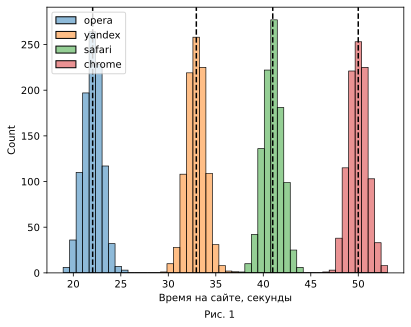

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

rng = np.random.default_rng()

df = pd.DataFrame(
    data={
        'opera': rng.normal(loc=22, scale=1, size=1000),
        'yandex': rng.normal(loc=33, scale=1, size=1000),
        'safari': rng.normal(loc=41, scale=1, size=1000),
        'chrome': rng.normal(loc=50, scale=1, size=1000),
    }
)

sns.histplot(data=df, bins=50)
plt.axvline(x=df.opera.mean(), color='black', linestyle='--')
plt.axvline(x=df.yandex.mean(), color='black', linestyle='--')
plt.axvline(x=df.safari.mean(), color='black', linestyle='--')
plt.axvline(x=df.chrome.mean(), color='black', linestyle='--')
plt.xlabel('Время на сайте, секунды')
plt.figtext(x=0.5, y=-0.02, s='Рис. 1', ha='center')

plt.show()

*(В графике выше и далее пунктиром отмечены средние значения каждой группы)*

Глядя на получившийся результат хочется сказать, что, действительно, среднее время на сайте зависит от браузера пользователя (или точнее будет сказать, что два эти показателя связаны – без уточнения в какую сторону).

А теперь представьте, что гистограммы выглядят вот так:

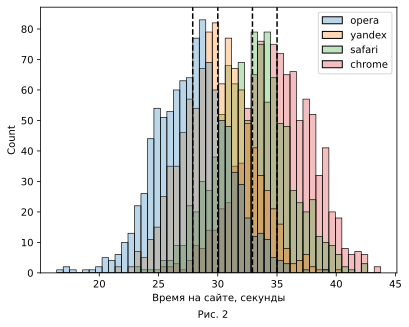

In [18]:
df = pd.DataFrame(
    data={
        'opera': rng.normal(loc=28, scale=3, size=1000),
        'yandex': rng.normal(loc=30, scale=3, size=1000),
        'safari': rng.normal(loc=33, scale=3, size=1000),
        'chrome': rng.normal(loc=35, scale=3, size=1000),
    }
)

sns.histplot(data=df, bins=50, alpha=0.3)
plt.axvline(x=df.opera.mean(), color='black', linestyle='--')
plt.axvline(x=df.yandex.mean(), color='black', linestyle='--')
plt.axvline(x=df.safari.mean(), color='black', linestyle='--')
plt.axvline(x=df.chrome.mean(), color='black', linestyle='--')
plt.xlabel('Время на сайте, секунды')
plt.figtext(x=0.5, y=-0.02, s='Рис. 2', ha='center')

plt.show()

В данном случае тоже у пользователей разных браузеров среднее время на сайте (см. пунктирные линии) – разное. 
Однако из-за сильно пересекающихся гистограмм появляются подозрения, что получвишаяся разница средних – случайна.
Например, накопится у нас побольше данных или возьмём данные за другой период, то уже не пользователи chrome будут проводить больше всего времени на сайте, а кто-то другие.

Поэтому в данном случае захочется с меньшей уверенностью заявлять о наличии связи между браузером пользователя и временем на сайте.

Для того, чтобы оценить нашу уверенность в наличии зависимости можно:
- Оценить вероятность, с которой полученные (и ещё более сильно отличающиеся) группы могли бы быть извлечены из одной совокупности (то есть, что на самом деле если рассмотреть вообще всех пользователе разных браузеров, то в среднем они проводят одинаковое время на сайте)
- Если эта вероятность ($p-value$) маленькая, то будем считать верным обратное, что выборки извлечены из разных совокупностей 
- Для этого можно провести дисперсионный анализ с использованием критерия Фишера.

## F-статистика (критерий Фишера)

### Что это
F-статистика – используется для определения вероятности, с которой получившиеся (и более сильно отличающиеся) выборки могли быть извлечены из одной совокупности.

Если эта вероятность ($p-value$) маленькая (меньше или равна уровня значимости $\alpha$, который задал исследователь), то для исследователя это сигнал к тому, чтобы считать выборки извлечёнными из разных совокупностей (другими словами, отклонить $H_0$ – гипотезу, что выборки извлечены из одной совокупности).

И, наоборот, если вероятность не такая маленькая (больше $\alpha$), то для исследователя это сигнал к тому, чтобы посчитать, что выборки извлечены из одной совокупности (другими словами НЕ отклонить $H_0$).

### График распределения F-статистики

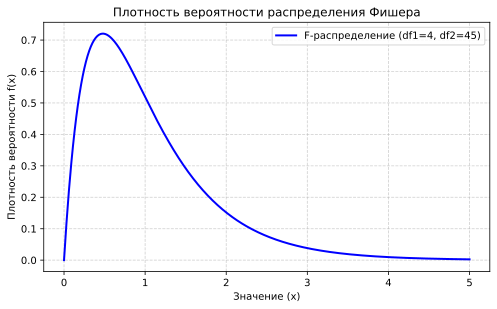

In [ ]:
from scipy.stats import f

# Параметры степеней свободы (df1, df2)
df1, df2 = 4, 45

# Создаем сетку значений по оси X
x = np.linspace(0, 5, 500)

# Вычисляем плотность вероятности (PDF) для распределения Фишера
y = f.pdf(x, df1, df2)
f.pdf()

# Строим график
plt.figure(figsize=(8, 4.5))
plt.plot(
    x, y, label=f'F-распределение (df1={df1}, df2={df2})', color='blue', lw=2
)
plt.title('Плотность вероятности распределения Фишера')
plt.xlabel('Значение (x)')
plt.ylabel('Плотность вероятности f(x)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.show()

### Как это вычислить
Для расчёта F-статистики используется следующая идея: 
1. Предположим, что все выборки извлечены из одной совокупности
2. У этой совокупности есть дисперсия ($\sigma^2$)
3. Мы не знаем чему равна $\sigma^2$, но можем оценить её двумя способами:
	1. Способ 1 – Внутригрупповая оценка дисперсии
	   
	   Алгоритм расчёта:
		1. Рассчитать оценку дисперсии внутри каждой группы:
			1. $S^2_{группа_{j}} = \sum_{i=1}^{n} \frac{(x_i - \bar{X}_{группа_{j}})^2}{n - 1}$, где $n$ – количество элементов выборки
		2. Рассчитать их среднее арифметическое (предполагается, что в каждой выборке по n элементов)
			1. $S^2_{вну.} = \frac{ \sum_{j=1}^{k} S^2_{группа_{j}} }{k}$, где $k$ – число групп
	2. Способ 2 – Межгрупповая оценка дисперсии
	   
	   Алгоритм расчёта:
		1. Вспомнить, что $\sigma_{X}^{2} = \sigma_{\bar{X}}^{2} \cdot n$, где $\sigma_{\bar{X}}^{2}$ – это дисперсия среднего значения выборки размера $n$ из совокупности, это же стандартная ошибка (SE - Standard Error)
		2. Тогда  $S_{меж.}^2 = \hat{ \sigma_{X}^{2} } = \hat{ \sigma_{\bar{X}}^{2} } \cdot n$
		3. На основе имеющихся данных рассчитать дисперсию среднего значения выборки размера n из совокупности (стандартную ошибку)
			1. $\hat{ \sigma_{\bar{X}}^{2} } = \frac{\sum_{j=1}^{k} (\bar{X}_{группа_{j}} - \bar{\bar{X}})^2}{k-1}$
		4. Рассчитать межгрупповую оценку дисперсии
			1. $S_{меж.}^2 = \hat{ \sigma_{X}^{2} } = \hat{ \sigma_{\bar{X}}^{2} } \cdot n = \frac{\sum_{j=1}^{k} (\bar{X}_{группа_{j}} - \bar{\bar{X}})^2}{k-1} \cdot n$
4. Посчитать дисперсию двумя способами (см. пп. 3.1. и 3.2.) и найти их отношение – это и будет F-статистика (критерий Фишера)
	1. $F = \frac{S_{меж.}^{2}}{S_{вну.}^{2}}$

### Почему это работает?
$F = \frac{S_{меж.}^{2}}{S_{вну.}^{2}}$

$S_{меж.}^{2}$ (межгрупповая оценка дисперсии) – т.к. групп обычно мало (скажем, меньше 10), то, по сути, это мера разброса средних значений групп.

А $S_{вну.}^{2}$ - это средний разброс внутри групп.

Тогда $F = \frac{S_{меж.}^{2}}{S_{вну.}^{2}} = \frac{\text{разброс средних значений групп}}{\text{средний разброс внутри групп}}$

Теперь видно, что чем больше отношение "разницы" между группами (разброс средних значений групп) к тому как сильно могут пересекаться их гистограммы (средний разброс внутри групп), тем менее вероятно кажется, что группы взяты из одной совокупности.

### Предпосылки
Взяты из учебника Стентона Гланца "Медико-биологическая статистика" (стр. 58-59).

Данная математическая модель критерия Фишера построена на основе предпосылок:
- Выборки независимы
- Совокупность распределена нормально
- Выборки случайным образом извлечены из совокупностей
- Дисперсии выборок равны

Как отмечает автор, если хотя бы одна из предпосылок не выполняется, то данным критерием нельзя пользоваться, как и дисперсионным анализом в целом.

## Самостоятельное построение гистограммы F-статистики методом монте-карло

План:
1. Сгенерировать совокупность
2. Взять k выборок (один элемент может попасть только в одну выборку) одинакового размера n из совокупности
3. Рассчитать оценку межгрупповой дисперсии
4. Рассчитать оценку внутригрупповой дисперсии
5. Рассчитать критерий Фишера
6. 10 000 раз (или другое число) повторить пп. 2 - 6 
7. Построить распределение критерия Фишера



In [29]:
def calculate_variance_estimations_and_f_statistic(population: np.array, samples_count: int, sample_size: int):

    #Взятие samples_count выборок из совокупности (population), каждая размера sample_size.
    #Каждый элемент можно выбрать всего один раз (см. "replace=False"), 
    #поскольку в реальной жизни элемент совокупности не может (или, по крайней мере, не должен) попадать в разные выборки.
    
    #Решил поставить replace=True (возможно, так правильнее).
    samples = np.random.choice(a=population, size=(samples_count, sample_size), replace=True) #

    #Расчёт межгрупповой дисперсии
    #Приведение к np.array, чтобы можно было считать среднее с помощью метода mean()
    samples_means = np.array(
        [samples[_].mean() for _ in range(samples_count)]
        )
    sum_squared_deviations_of_means = ((samples_means - samples.mean())**2).sum()
    standard_error = (sum_squared_deviations_of_means/(samples_count - 1))**0.5
    variance_between = standard_error**2 * sample_size


    #Расчёт внутригрупповой дисперсии
    sum_squared_deviations = ((samples - samples.mean())**2).sum()
    variance_within = sum_squared_deviations / (samples_count * sample_size - 1)

    f_statistic = variance_between / variance_within

    return variance_between, variance_within, f_statistic

In [45]:
#Импорт функции для прогресс бара при запуске цикла
from tqdm.auto import tqdm

rng = np.random.default_rng()
population_size = 100000
samples_count = 5
sample_size = 10

In [46]:
uniform__population = rng.uniform(low=0, high=1, size=population_size)
standard_normal__population = rng.normal(loc=0, scale=1, size=population_size)
normal__population = rng.normal(loc=50, scale=13, size=population_size)
pareto__population = rng.pareto(a=1, size=population_size)

normal_1__population = rng.normal(loc=-50, scale=10, size=int(population_size / 2))
normal_2__population = rng.normal(loc=33, scale=20, size=int(population_size / 2))

bimodal__population = np.concat([normal_1__population, normal_2__population])

populations__dict = {
    'standard_normal': {
            'population': standard_normal__population, 
            'variances_between': [],
            'variances_within': [],
            'f_statistics': []
            },
    'normal': {
            'population': normal__population, 
            'variances_between': [],
            'variances_within': [],
            'f_statistics': []
            },
    'bimodal': {
            'population': bimodal__population, 
            'variances_between': [],
            'variances_within': [],
            'f_statistics': []
            },
    'uniform': {
        'population': uniform__population, 
        'variances_between': [],
        'variances_within': [],
        'f_statistics': []
        },
    'pareto': {
        'population': pareto__population, 
        'variances_between': [],
        'variances_within': [],
        'f_statistics': []
        }
}

In [47]:
for population_name, _ in populations__dict.items():

    for _ in tqdm(range(10000)):
        variance_between, variance_within, f_statistic = calculate_variance_estimations_and_f_statistic(
            population=populations__dict[population_name]['population'], 
            samples_count=samples_count, 
            sample_size=sample_size
            )

        populations__dict[population_name]['variances_between'].append(variance_between)
        populations__dict[population_name]['variances_within'].append(variance_within)
        populations__dict[population_name]['f_statistics'].append(f_statistic)

  0%|          | 0/10000 [00:00<?, ?it/s]

  0%|          | 0/10000 [00:00<?, ?it/s]

  0%|          | 0/10000 [00:00<?, ?it/s]

  0%|          | 0/10000 [00:00<?, ?it/s]

  0%|          | 0/10000 [00:00<?, ?it/s]

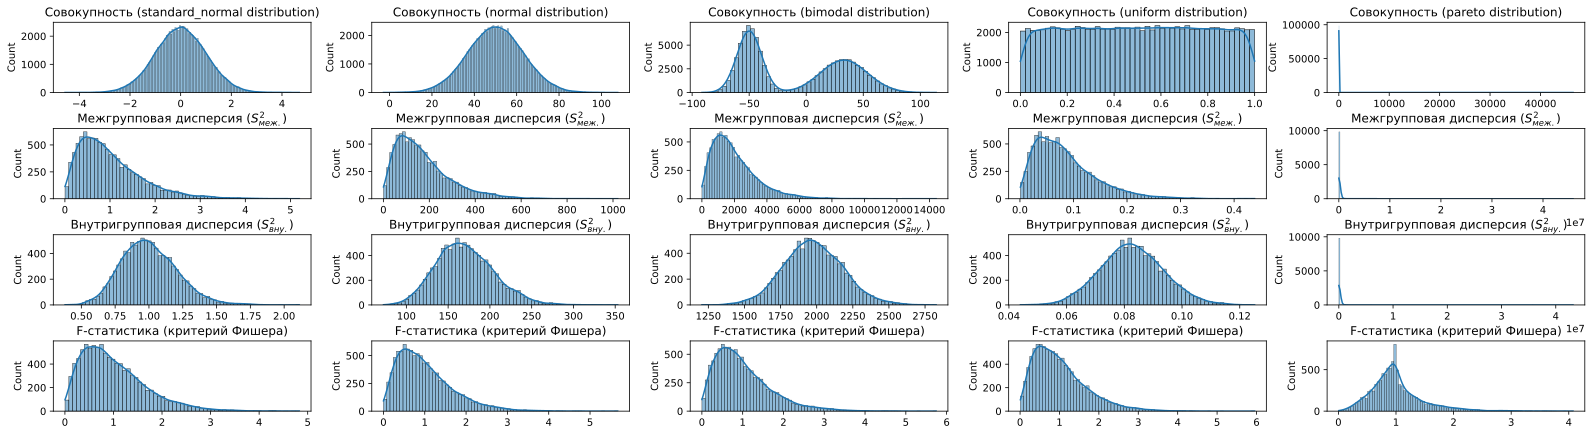

In [48]:
fig, axes = plt.subplots(nrows=4, ncols=5, figsize=(22, 6))
fig.tight_layout(h_pad=1.5, w_pad=3) #h_pad - это height padding (отступ по высоте между графиками), w_pad - это width padding

i = 0
for population_name, _ in populations__dict.items():
    axes[0, i].set_title(f'Совокупность ({population_name} distribution)')
    sns.histplot(data=populations__dict[population_name]['population'], kde=True, ax=axes[0, i])

    axes[1, i].set_title('Межгрупповая дисперсия $(S^{2}_{меж.})$')
    sns.histplot(data=populations__dict[population_name]['variances_between'], kde=True, ax=axes[1, i])

    axes[2, i].set_title('Внутригрупповая дисперсия $(S^{2}_{вну.})$')
    sns.histplot(data=populations__dict[population_name]['variances_within'], kde=True, ax=axes[2, i])

    axes[3, i].set_title('F-статистика (критерий Фишера)')
    sns.histplot(data=populations__dict[population_name]['f_statistics'], kde=True, ax=axes[3, i])

    i+=1

На рисунке выше представлены гистограммы F-статистик (см. нижние графики), посчитанные для совокупностей, имеющих разное распределение (см. верхние графики).

Исходя из [предпосылок](#предпосылки) имеет смысл работать с F-статистикой только если совокупность распределена нормально (см. левые два столбца графиков).

Поэтому F-статистики для совокупностей с другими распределениями (см. правые три столбца графиков) были построены исключительно из любопытсва.

Гистограммы F-статистики у нормально распределённых совокупностей (см. два левых графика в нижней строке) получились дейсвительно очень похожими на [теоретическое распределение](#график-распределения-f-статистики).

Остальные графики в целом тоже похожи, но в меньшей степени (см. три правых графика в нижней строке).

In [49]:
print(
    round(np.percentile(populations__dict['standard_normal']['f_statistics'], 95), 4),
    round(np.percentile(populations__dict['normal']['f_statistics'], 95), 4),
    round(np.percentile(populations__dict['bimodal']['f_statistics'], 95), 4),
    round(np.percentile(populations__dict['uniform']['f_statistics'], 95), 4),
    round(np.percentile(populations__dict['pareto']['f_statistics'], 95), 4),
)

2.2795 2.2908 2.3289 2.3101 1.888


Также в предыдщей ячейке представлены критические значения F-статистики для уровня значимости $\alpha$ = 0.05.

Видно, что самые близкие по значениям получились у нормально распределённых совокупностей.